# DNN Challenge 1: template notebook

This notebook **loads the data**, gives you **space for your model and your training**, and **exports your trained
network** as the single ONNX file you submit. It finishes by running the official checker.

Read `PROBLEM_STATEMENT.md` first. The rules in short:
- only the layers C1–C5 and F1–F2, each used at most once;
- at most 75,000 parameters;
- CNNs only, with no attention and no extra learnable parameters;
- all preprocessing inside the model.

**How to use it.** Run the cells top to bottom once. The example baseline trains in a few minutes on a GPU and
reaches about 67% on the validation set. Then replace the two marked sections, **YOUR MODEL** and **YOUR
TRAINING**, with your own design. Leave the export and check cells at the end unchanged.

## 0. Setup

In [2]:
!pip -q install onnx onnxscript onnxruntime
import os, time, copy, math, random, subprocess, sys, urllib.request
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

TEAM_NAME = "Santa_Claude"
TRAIN_ON_VAL = False   # keep False for this experiment: val must stay unseen to compare honestly
SEED = 0
CLASS_W = {"qpsk": 1.3, "16qam": 1.5, "ofdm": 1.2}   # all other classes 1.06
DATA_DIR = "data"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

os.makedirs(DATA_DIR, exist_ok=True)
BASE = "https://github.com/shashankvatedka/Deep-Learning-2026/releases/download/cnn/"
for name in ["train.npz", "val.npz", "check_submission.py"]:
    if not os.path.exists(os.path.join(DATA_DIR, name)):
        urllib.request.urlretrieve(BASE + name, os.path.join(DATA_DIR, name))

torch 2.11.0+cu130 | device: cuda


## 1. Load the data

`x` holds 32 × 64 log-magnitude spectrograms in dB:
- rows are frequency, from −125 kHz (row 0) through 0 Hz (row 16) to +117 kHz (row 31). **The frequency axis is
  circular**: row 31 and row 0 are neighbours;
- columns are time (64 frames, 4.16 ms in total);
- `y` holds the labels 0–7.

The model always receives `x` with a channel axis, shape `(N, 1, 32, 64)`, in float32.

In [3]:
tr = np.load(os.path.join(DATA_DIR, "train.npz")); va = np.load(os.path.join(DATA_DIR, "val.npz"))
CLASSES = [str(c) for c in tr["classes"]]
f32 = lambda a: torch.from_numpy(a.astype(np.float32))
x_train, y_train = f32(tr["x"]).unsqueeze(1), torch.from_numpy(tr["y"])
snr_train, sps_train = f32(tr["snr_db"]), f32(tr["sps"])          # metadata: used only by the noise augmentation
x_val, y_val, snr_val = f32(va["x"]).unsqueeze(1), torch.from_numpy(va["y"]), va["snr_db"]
if TRAIN_ON_VAL:
    x_train, y_train = torch.cat([x_train, x_val]), torch.cat([y_train, y_val])
    snr_train, sps_train = torch.cat([snr_train, f32(va["snr_db"])]), torch.cat([sps_train, f32(va["sps"])])
print("train", tuple(x_train.shape), "| val", tuple(x_val.shape))

train (40000, 1, 32, 64) | val (8000, 1, 32, 64)


In [4]:
# ---- space for your own data exploration ----


## 2. YOUR MODEL

Replace `Model` with your own design. The checker only cares about the **exported graph**, so you may use any
PyTorch code, as long as the exported network uses nothing but:

| item | layer | out | kernel |
|---|---|---|---|
| C1 | `nn.Conv2d(in, 16, 5, ...)` | 16 | 5×5 |
| C2 | `nn.Conv2d(in, 32, 3, ...)` | 32 | 3×3 |
| C3 | `nn.Conv2d(in, 32, 3, ...)` | 32 | 3×3 |
| C4 | `nn.Conv2d(in, 64, 3, ...)` | 64 | 3×3 |
| C5 | `nn.Conv2d(in, 32, 1, ...)` | 32 | 1×1 |
| F1 | `nn.Linear(in, 64)` | 64 | – |
| F2 | `nn.Linear(in, 8)` | 8 | – |

plus parameter-free operations and per-channel normalisation layers. Each item may be used at most once, so call
each layer exactly once in `forward()`.

**Preprocessing goes inside `forward()`.** The organisers feed the raw dB values.

The example below is the baseline: a plain LeNet-style chain with a flatten, 66,152 parameters, about 67% on
validation.

In [5]:
LN10_10 = math.log(10) / 10

def cpad(x, pf, pt):
    """circular padding along frequency (FFT bins wrap around), zero padding along time"""
    x = torch.cat([x[:, :, -pf:], x, x[:, :, :pf]], 2)
    return F.pad(x, (pt, pt, 0, 0))

def std(v, dim):
    return torch.sqrt(((v - v.mean(dim, keepdim=True)) ** 2).mean(dim) + 1e-6)


class Model(nn.Module):
    """Fixed (parameter-free) front-end -> C1 -> C2(stride) -> C3(+res) -> pool -> C4 -> C5(+res) -> stats -> F1 -> F2"""

    def __init__(self):
        super().__init__()
        self.c1, self.b1 = nn.Conv2d(6, 16, 5), nn.BatchNorm2d(16)                                     # C1
        self.c2, self.b2 = nn.Conv2d(16, 32, 3, stride=(1, 2), dilation=(1, 2)), nn.BatchNorm2d(32)    # C2
        self.c3, self.b3 = nn.Conv2d(32, 32, 3), nn.BatchNorm2d(32)                                    # C3
        self.c4, self.b4 = nn.Conv2d(32, 64, 3, dilation=(1, 2)), nn.BatchNorm2d(64)                   # C4
        self.c5, self.b5 = nn.Conv2d(64, 32, 1), nn.BatchNorm2d(32)                                    # C5
        self.bnf = nn.BatchNorm1d(172)
        self.f1, self.f2 = nn.Linear(172, 64), nn.Linear(64, 8)                                        # F1, F2
        self.drop = nn.Dropout(0.1)

    @staticmethod
    def frontend(x):                                    # x: (N,1,32,64) raw dB
        mu = x.mean((2, 3), keepdim=True)
        xs = (x - mu) / torch.sqrt(((x - mu) ** 2).mean((2, 3), keepdim=True) + 1e-4)   # standardised dB
        p = torch.exp((x - x.amax((2, 3), keepdim=True)) * LN10_10)                       # linear power ...
        p = p / (p.mean((2, 3), keepdim=True) + 1e-8)                                     # ... with unit mean
        e = p.sum(2, keepdim=True)                                                        # frame energy
        img = torch.cat([
            xs,                                                                 # db
            torch.log1p(p) - 0.7,                                               # lin
            (torch.log(p + 1e-6) - torch.log(e / 32 + 1e-6)) * 0.25,            # fnorm: per-frame normalised (fading removed)
            F.pad(xs[..., 1:] - xs[..., :-1], (1, 0, 0, 0)) * 0.7,              # tdiff: frame-to-frame change
            torch.cat([xs[:, :, :1], torch.flip(xs[:, :, 1:], [2])], 2),        # conj: mirrored spectrum f -> -f
            xs - xs.mean(3, keepdim=True),                                      # dev: deviation from mean spectrum
        ], 1)
        # 12 global physics statistics
        e = e.squeeze(2); le = torch.log(e + 1e-6); de = le[..., 1:] - le[..., :-1]
        r = e / (F.avg_pool1d(F.pad(e, (4, 4), mode="replicate"), 9, 1) + 1e-6)          # fading-normalised envelope
        rm = r.mean(-1, keepdim=True); rv = ((r - rm) ** 2).mean(-1, keepdim=True)
        kurt = (((r - rm) ** 4).mean(-1, keepdim=True) / (rv ** 2 + 1e-6)).squeeze(-1)
        psd = p.mean(3); lpsd = torch.log(psd + 1e-6); rowstd = std(xs, -1)
        s = torch.cat([std(le, -1), std(de, -1), de.abs().mean(-1), torch.log(e.amax(-1) / e.mean(-1)),
                       lpsd.mean(-1) - torch.log(psd.mean(-1)), std(lpsd, -1), torch.log(rv.squeeze(-1) + 1e-6),
                       torch.log(kurt + 1e-3), (rowstd * (psd / psd.sum(-1, keepdim=True))).sum(-1),
                       rowstd.mean(-1), rowstd.amax(-1), torch.log((psd * psd).sum(-1) / psd.sum(-1) ** 2 * 32)], 1)
        return img, s

    def forward(self, x):
        img, s = self.frontend(x)
        h1 = F.silu(self.b1(self.c1(cpad(img, 2, 2))))                     # 16 x 32 x 64
        h2 = F.silu(self.b2(self.c2(cpad(h1, 1, 2))))                      # 32 x 32 x 32  (stride 2 in time)
        h3 = F.silu(self.b3(self.c3(cpad(h2, 1, 1)))) + h2                 # 32 x 32 x 32  (residual)
        h3 = F.max_pool2d(h3, (1, 4))                                      # 32 x 32 x 8
        h4 = F.silu(self.b4(self.c4(cpad(h3, 1, 2))))                      # 64 x 32 x 8
        h5 = F.silu(self.b5(self.c5(h4)) + h3)                             # 32 x 32 x 8   (C5 residual)
        m5 = h5.mean((2, 3))
        z = torch.cat([m5, h5.amax((2, 3)), torch.sqrt(((h5 - m5[..., None, None]) ** 2).mean((2, 3)) + 1e-5),
                       h4.mean((2, 3)), s], 1)                             # 96 + 64 + 12 = 172
        return self.f2(self.drop(F.silu(self.f1(self.bnf(z)))))            # logits (no softmax)


def budget(model):
    n = sum(m.weight.numel() + m.weight.shape[0] for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear)))
    print(f"inventory parameters (incl. biases): {n:,} / 75,000"); return n

In [6]:
# ---- space for your own model code ----
model = Model().to(device); budget(model)

inventory parameters (incl. biases): 48,472 / 75,000


48472

## 3. YOUR TRAINING

Replace this with your own training: augmentation, optimiser, schedule, regularisation and so on. You may also
train on `val.npz`. Below is a minimal loop: Adam, no augmentation, keeping the epoch with the best validation
accuracy.

In [7]:
EPOCHS, BS, LR, WD, LS, EMA_DECAY, NOISE_P = 150, 512, 4e-3, 1e-2, 0.05, 0.999, 0.3   # verified 82.05% recipe
FI, TI = torch.arange(32, device=device), torch.arange(64, device=device)
CONJ = torch.cat([FI[:1], torch.flip(FI[1:], [0])])                    # row k -> (32-k) % 32
HANN = 0.5 - 0.5 * torch.cos(2 * math.pi * torch.arange(32, device=device) / 32)

def add_noise(x, snr_db, sps, target_db):
    """re-noise spectrograms from Es/N0 = snr_db down to target_db.
    Dataset model (checked on train.npz): power normalised to 1, Es/N0 = Ps*sps/sigma^2.
    Extra white noise goes through the receiver's exact STFT; random phase per bin for the signal."""
    sig2 = 1.0 / (1.0 + torch.pow(10.0, snr_db / 10) / sps); ps = 1.0 - sig2
    sig2_new = ps * sps / torch.pow(10.0, target_db / 10)
    extra = torch.clamp(sig2_new - sig2, min=0)
    amp = torch.exp(x[:, 0] * (LN10_10 / 2))
    ph = torch.rand(len(x), 32, 64, device=device) * (2 * math.pi)
    z = torch.view_as_complex((torch.randn(len(x), 1040, 2, device=device) * math.sqrt(0.5)).contiguous())
    N = torch.fft.fftshift(torch.fft.fft(z.unfold(1, 32, 16)[:, :64] * HANN, dim=-1), dim=-1).transpose(1, 2)
    p = (amp * torch.exp(1j * ph) + N * torch.sqrt(extra)[:, None, None]).abs() ** 2 / (ps + sig2_new)[:, None, None]
    return (10 * torch.log10(p + 1e-12))[:, None]

def augment(x, snr, sps):
    n = len(x)
    m = torch.rand(n, device=device) < NOISE_P                                   # noise injection (p = 0.3)
    if m.any():
        tgt = -4 + torch.rand(int(m.sum()), device=device) * (snr[m] + 4).clamp(min=0)
        x = x.clone(); x[m] = add_noise(x[m], snr[m], sps[m], tgt)
    m = torch.rand(n, device=device) < 0.5; x[m] = x[m][:, :, CONJ]              # conjugation f -> -f
    m = torch.rand(n, device=device) < 0.5; x[m] = torch.flip(x[m], [3])         # time reversal
    sh = torch.randint(-3, 4, (n,), device=device)                               # +-3 bin frequency offset
    x = torch.gather(x, 2, ((FI[None] - sh[:, None]) % 32)[:, None, :, None].expand(-1, 1, -1, 64))
    sh = torch.randint(0, 64, (n,), device=device)                               # circular time shift
    return torch.gather(x, 3, ((TI[None] - sh[:, None]) % 64)[:, None, None, :].expand(-1, 1, 32, -1))

@torch.no_grad()
def predict(m, x, bs=1000):
    m.eval(); return torch.cat([m(x[i:i + bs].to(device)).argmax(1).cpu() for i in range(0, len(x), bs)])

QPSK, QAM16 = CLASSES.index("qpsk"), CLASSES.index("16qam")

def train_model(class_w, seed):
    """trains one model with per-class cross-entropy weights"""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
    torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
    model = Model().to(device)
    CW = torch.tensor([class_w.get(c, 1.0) for c in CLASSES], device=device)   # class weights
    xtr, ytr, str_, ptr = x_train.to(device), y_train.to(device), snr_train.to(device), sps_train.to(device)
    ema = copy.deepcopy(model).eval()                                   # weight EMA of this single run
    for q in ema.parameters(): q.requires_grad_(False)
    opt = torch.optim.AdamW([{"params": [q for q in model.parameters() if q.ndim > 1], "weight_decay": WD},
                             {"params": [q for q in model.parameters() if q.ndim <= 1], "weight_decay": 0}], lr=LR)
    spe = len(xtr) // BS
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * spe, pct_start=0.1,
                                                div_factor=20, final_div_factor=500)
    g = torch.Generator().manual_seed(seed); step = 0; hist = []; t0 = time.time()
    for ep in range(EPOCHS):
        model.train(); tl = 0.0
        perm = torch.randperm(len(xtr), generator=g).to(device)
        for i in range(spe):
            idx = perm[i * BS:(i + 1) * BS]
            li = F.cross_entropy(model(augment(xtr[idx].clone(), str_[idx], ptr[idx])), ytr[idx], weight=CW,
                                 label_smoothing=LS, reduction="none")
            loss = li.sum() / CW[ytr[idx]].sum()          # weighted mean (alpha = 1 -> identical to the original loss)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            tl += loss.item(); step += 1
            with torch.no_grad():
                d = min(EMA_DECAY, (1 + step) / (10 + step))
                for pe, pm in zip(ema.parameters(), model.parameters()): pe.mul_(d).add_(pm.detach(), alpha=1 - d)
        if (ep + 1) % 5 == 0 or ep == 0:
            acc = (predict(model, x_val) == y_val).float().mean().item()
            hist.append((ep + 1, tl / spe, acc))
            print(f"epoch {ep+1:3d}  loss {tl/spe:.4f}  val acc {acc:.4f}  ({time.time()-t0:.0f} s)")

    # BatchNorm statistics for the EMA weights: one pass over un-augmented training data
    ema.train()
    with torch.no_grad():
        for mod in ema.modules():
            if isinstance(mod, nn.modules.batchnorm._BatchNorm): mod.reset_running_stats(); mod.momentum = None
        for i in range(0, min(len(xtr), 20000), 1000): ema(xtr[i:i + 1000])
    model = ema.eval()
    print(f"done in {(time.time()-t0)/60:.1f} min")
    return model, hist

print("class weights:", {c: CLASS_W.get(c, 1.0) for c in CLASSES})
model, hist = train_model(CLASS_W, SEED)

class weights: {'ook': 1.0, 'bpsk': 1.0, 'qpsk': 1.35, '16qam': 1.35, '2fsk': 1.0, '4fsk': 1.0, 'gmsk': 1.0, 'ofdm': 1.15}
epoch   1  loss 1.9625  val acc 0.3274  (15 s)
epoch   5  loss 1.0901  val acc 0.7284  (58 s)
epoch  10  loss 0.9557  val acc 0.6954  (114 s)
epoch  15  loss 0.9113  val acc 0.7713  (172 s)
epoch  20  loss 0.8890  val acc 0.7834  (229 s)
epoch  25  loss 0.8765  val acc 0.7968  (287 s)
epoch  30  loss 0.8629  val acc 0.8011  (344 s)
epoch  35  loss 0.8610  val acc 0.7946  (402 s)
epoch  40  loss 0.8559  val acc 0.8077  (459 s)
epoch  45  loss 0.8460  val acc 0.8111  (517 s)
epoch  50  loss 0.8477  val acc 0.7943  (574 s)
epoch  55  loss 0.8398  val acc 0.8061  (631 s)
epoch  60  loss 0.8380  val acc 0.8030  (689 s)
epoch  65  loss 0.8313  val acc 0.8016  (746 s)
epoch  70  loss 0.8283  val acc 0.8083  (803 s)
epoch  75  loss 0.8247  val acc 0.8140  (861 s)
epoch  80  loss 0.8181  val acc 0.8061  (918 s)
epoch  85  loss 0.8166  val acc 0.8130  (976 s)
epoch  90  loss

In [8]:
# ---- space for your own training / analysis code ----


In [9]:
pred = predict(model, x_val).numpy(); yv = va["y"]; ok = pred == yv
acc, le2, le4 = ok.mean(), ok[snr_val <= 2].mean(), ok[snr_val <= 4].mean()
cm = np.zeros((8, 8)); np.add.at(cm, (yv, pred), 1); cm /= cm.sum(1, keepdims=True)
BASE = dict(acc=0.8197, le2=0.558, le4=0.619)          # unweighted model, 3-seed mean (EMA, official val)
print(f"weighted : val {acc*100:.2f}% | <=2dB {le2*100:.2f}% | <=4dB {le4*100:.2f}%")
print(f"baseline : val {BASE['acc']*100:.2f}% | <=2dB {BASE['le2']*100:.2f}% | <=4dB {BASE['le4']*100:.2f}%   (seed range 81.76-82.20)")
print(f"difference: {100*(acc-BASE['acc']):+.2f} pts   (single run: differences within about +-0.3 pts are noise)")
print("\nper-class recall:", {c: round(float(cm[i, i]), 3) for i, c in enumerate(CLASSES)})
print(f"QPSK -> 16QAM {cm[QPSK, QAM16]:.3f} | 16QAM -> QPSK {cm[QAM16, QPSK]:.3f}")

weighted : val 81.81% | <=2dB 55.25% | <=4dB 61.52%
baseline : val 81.97% | <=2dB 55.80% | <=4dB 61.90%   (seed range 81.76-82.20)
difference: -0.16 pts   (single run: differences within about +-0.3 pts are noise)

per-class recall: {'ook': 0.941, 'bpsk': 0.814, 'qpsk': 0.746, '16qam': 0.626, '2fsk': 0.866, '4fsk': 0.887, 'gmsk': 0.887, 'ofdm': 0.778}
QPSK -> 16QAM 0.103 | 16QAM -> QPSK 0.182


val acc 0.8181 | Es/N0<=2dB 0.5525 | Es/N0<=4dB 0.6152


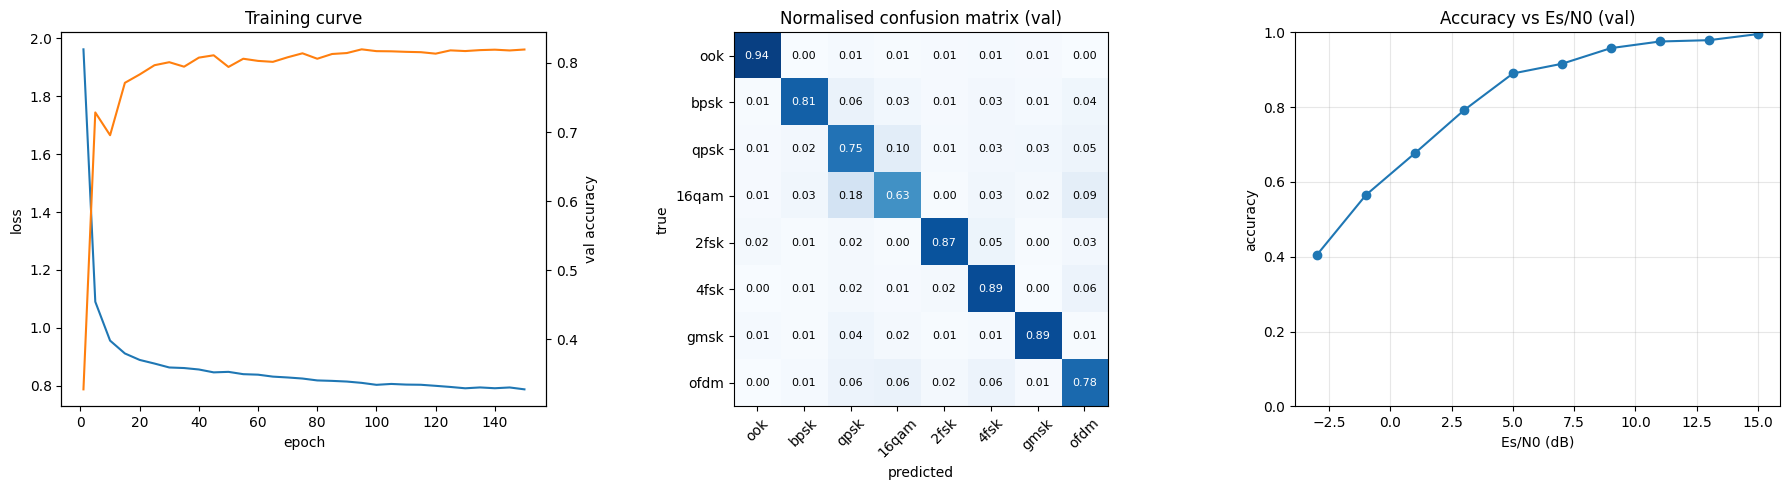

  ook    0.941
  bpsk   0.814
  qpsk   0.746
  16qam  0.626
  2fsk   0.866
  4fsk   0.887
  gmsk   0.887
  ofdm   0.778


In [10]:
pred = predict(model, x_val).numpy(); yv = va["y"]; ok = pred == yv
print(f"val acc {ok.mean():.4f} | Es/N0<=2dB {ok[snr_val<=2].mean():.4f} | Es/N0<=4dB {ok[snr_val<=4].mean():.4f}"
      + ("   (val was in the training set: optimistic)" if TRAIN_ON_VAL else ""))
cm = np.zeros((8, 8)); np.add.at(cm, (yv, pred), 1); cm /= cm.sum(1, keepdims=True)
edges = np.arange(-4, 17, 2); mids = (edges[:-1] + edges[1:]) / 2
acc_snr = [ok[(snr_val >= a) & (snr_val < b)].mean() for a, b in zip(edges[:-1], edges[1:])]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
h = np.array(hist)
ax[0].plot(h[:, 0], h[:, 1], label="train loss"); a2 = ax[0].twinx(); a2.plot(h[:, 0], h[:, 2], "C1", label="val acc (live)")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); a2.set_ylabel("val accuracy"); ax[0].set_title("Training curve")
im = ax[1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(8):
    for j in range(8):
        ax[1].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
ax[1].set_xticks(range(8)); ax[1].set_xticklabels(CLASSES, rotation=45); ax[1].set_yticks(range(8)); ax[1].set_yticklabels(CLASSES)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true"); ax[1].set_title("Normalised confusion matrix (val)")
ax[2].plot(mids, acc_snr, "o-"); ax[2].set_ylim(0, 1); ax[2].grid(alpha=0.3)
ax[2].set_xlabel("Es/N0 (dB)"); ax[2].set_ylabel("accuracy"); ax[2].set_title("Accuracy vs Es/N0 (val)")
plt.tight_layout(); plt.show()
for c, n in enumerate(CLASSES): print(f"  {n:6s} {ok[yv == c].mean():.3f}")

class   precision  recall   F1
ook         0.935   0.941  0.938
bpsk        0.898   0.814  0.854
qpsk        0.654   0.746  0.697
16qam       0.721   0.626  0.670
2fsk        0.909   0.866  0.887
4fsk        0.803   0.887  0.843
gmsk        0.912   0.887  0.899
ofdm        0.742   0.778  0.759
macro       0.822   0.818  0.818
parameters per layer: {'c1': 2416, 'c2': 4640, 'c3': 9248, 'c4': 18496, 'c5': 2080, 'f1': 11072, 'f2': 520}


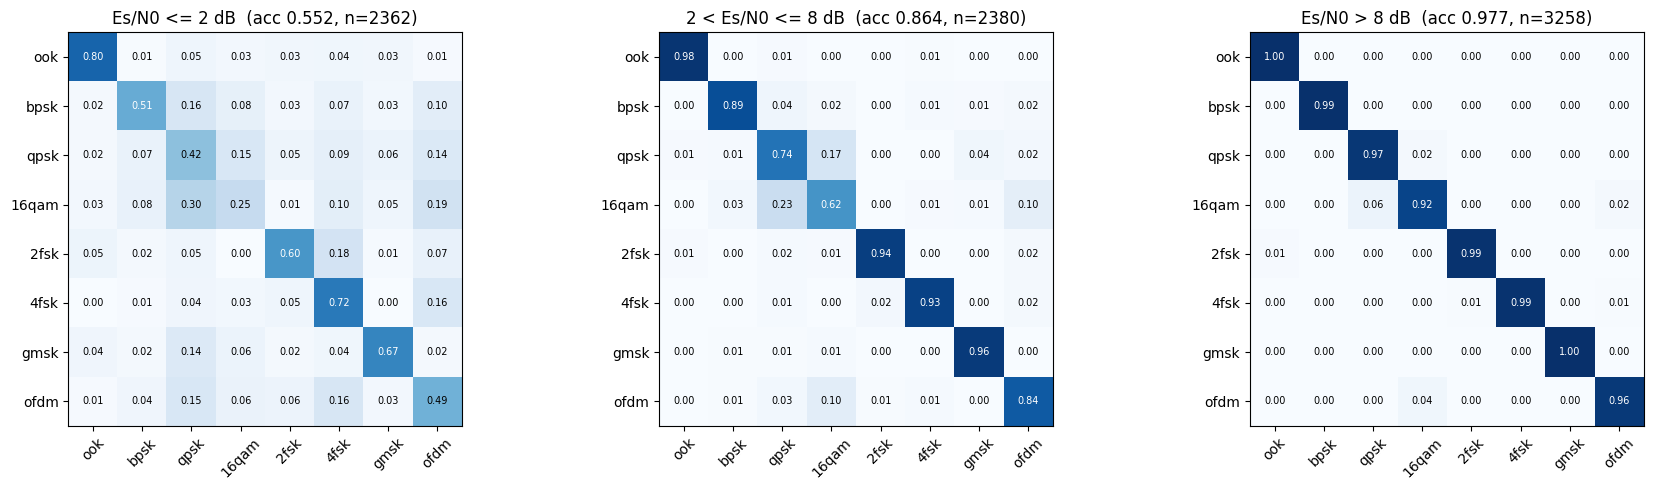

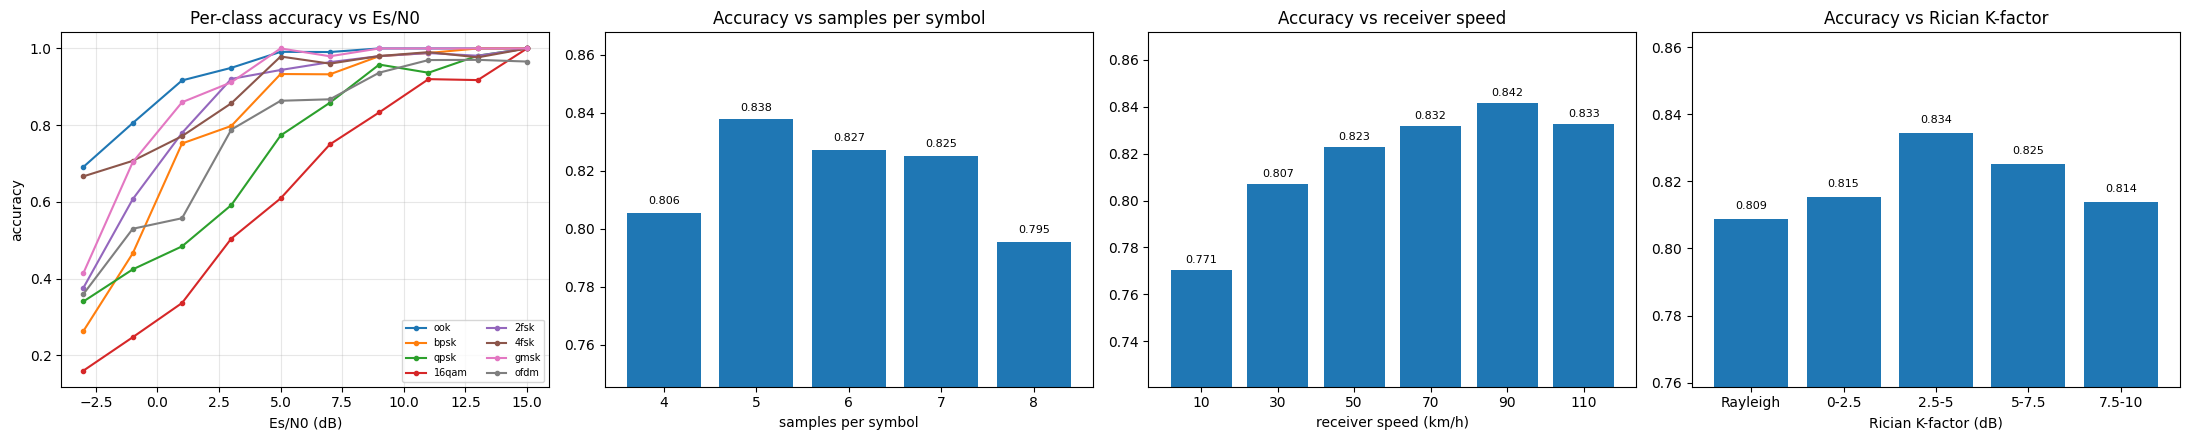

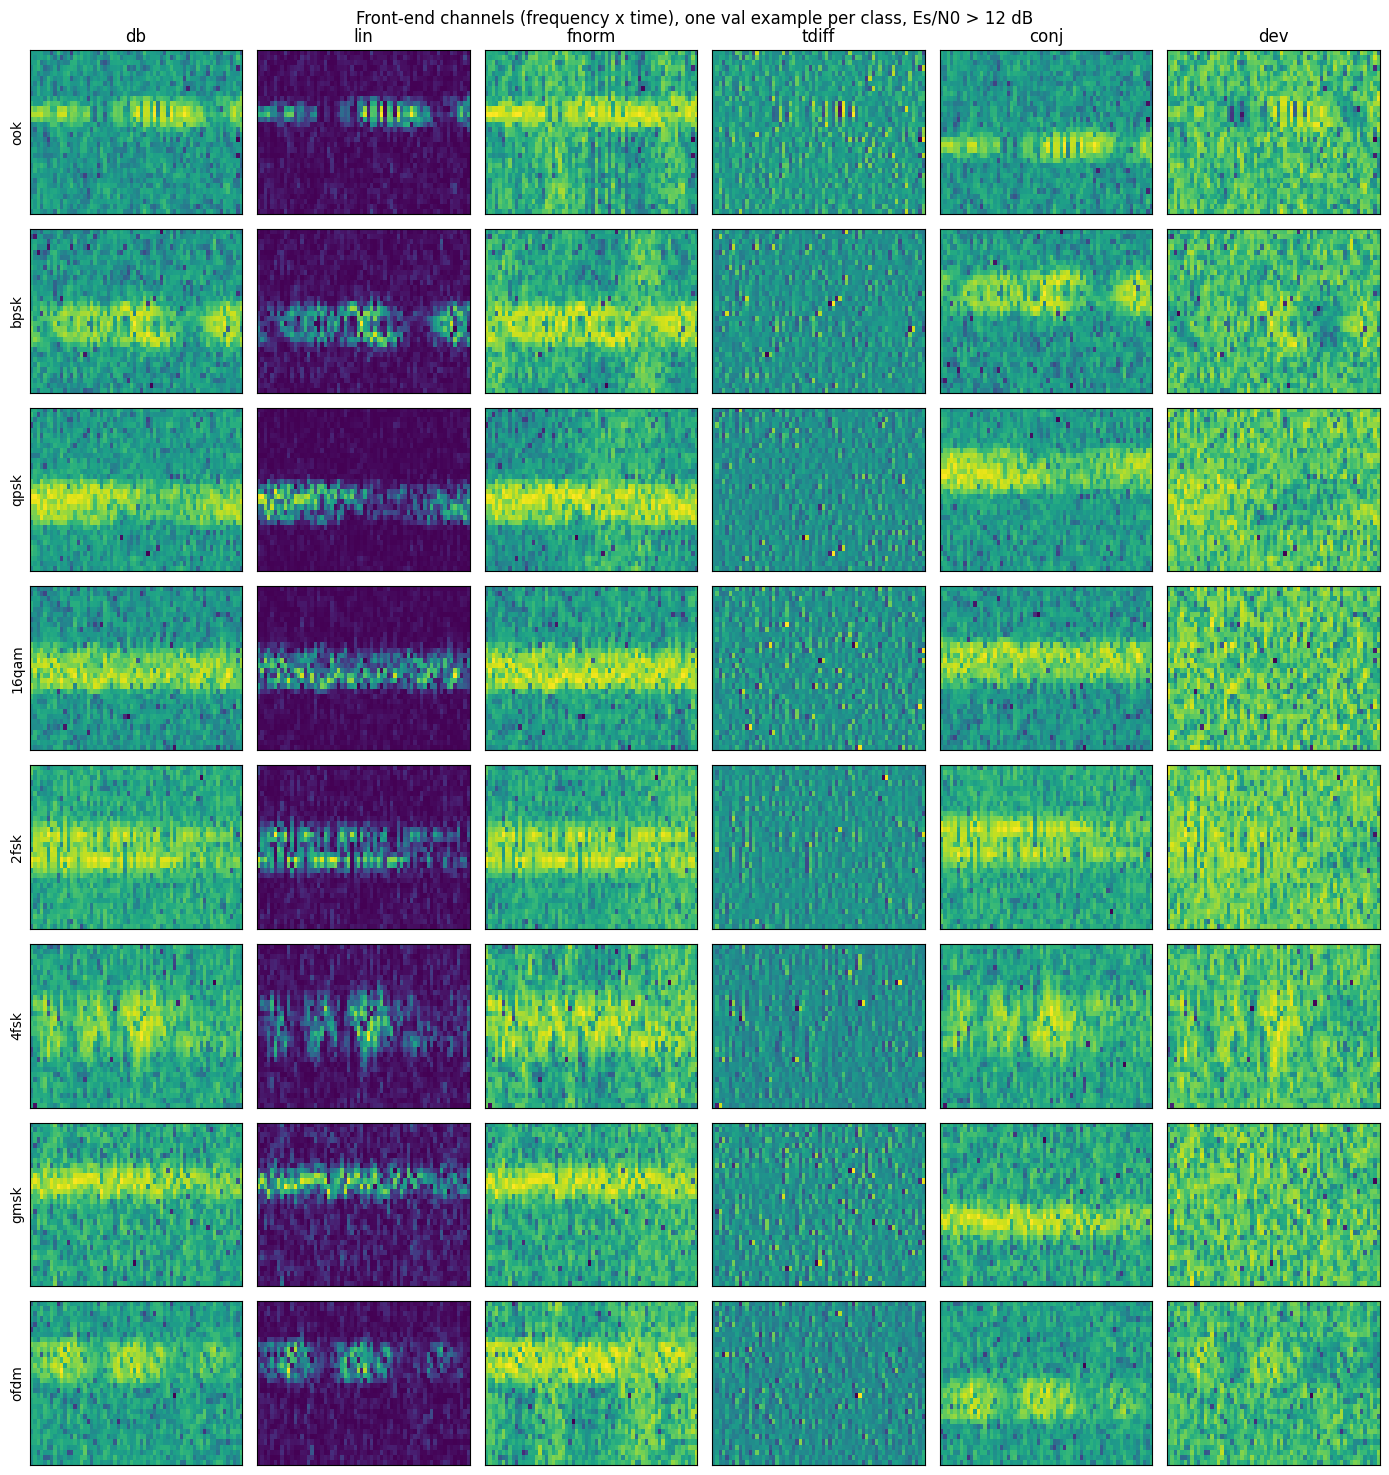

In [11]:
# ---- extra results for the report (computed after training; does not affect the model) ----
P, R_, F1 = [], [], []
for c in range(8):
    tp = ((pred == c) & (yv == c)).sum(); P.append(tp / max((pred == c).sum(), 1)); R_.append(tp / max((yv == c).sum(), 1))
    F1.append(2 * P[-1] * R_[-1] / max(P[-1] + R_[-1], 1e-9))
print(f"{'class':7s} precision  recall   F1")
for c, n in enumerate(CLASSES): print(f"{n:7s} {P[c]:9.3f} {R_[c]:7.3f} {F1[c]:6.3f}")
print(f"macro   {np.mean(P):9.3f} {np.mean(R_):7.3f} {np.mean(F1):6.3f}")
print("parameters per layer:", {n: m.weight.numel() + m.weight.shape[0] for n, m in model.named_modules()
                                if isinstance(m, (nn.Conv2d, nn.Linear))})

# (a) confusion matrices split by SNR: shows QPSK/16QAM confusion is a low-SNR effect
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (lo, hi, t) in zip(ax, [(-5, 2, "Es/N0 <= 2 dB"), (2, 8, "2 < Es/N0 <= 8 dB"), (8, 17, "Es/N0 > 8 dB")]):
    m = (snr_val > lo) & (snr_val <= hi); c_ = np.zeros((8, 8)); np.add.at(c_, (yv[m], pred[m]), 1); c_ /= c_.sum(1, keepdims=True)
    a.imshow(c_, cmap="Blues", vmin=0, vmax=1)
    for i in range(8):
        for j in range(8):
            a.text(j, i, f"{c_[i, j]:.2f}", ha="center", va="center", color="white" if c_[i, j] > 0.5 else "black", fontsize=7)
    a.set_xticks(range(8)); a.set_xticklabels(CLASSES, rotation=45); a.set_yticks(range(8)); a.set_yticklabels(CLASSES)
    a.set_title(f"{t}  (acc {ok[m].mean():.3f}, n={m.sum()})")
plt.tight_layout(); plt.show()

# (b) per-class accuracy vs Es/N0   (c) accuracy vs channel / receiver metadata
fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
for c, n in enumerate(CLASSES):
    ax[0].plot(mids, [ok[(yv == c) & (snr_val >= a) & (snr_val < b)].mean() for a, b in zip(edges[:-1], edges[1:])], "o-", ms=3, label=n)
ax[0].set_xlabel("Es/N0 (dB)"); ax[0].set_ylabel("accuracy"); ax[0].set_title("Per-class accuracy vs Es/N0"); ax[0].legend(fontsize=7, ncol=2); ax[0].grid(alpha=0.3)
kdb = np.where(np.isfinite(va["k_db"]), va["k_db"], -10.0)
for a, (v, nm, bins) in zip(ax[1:], [(va["sps"], "samples per symbol", np.linspace(4, 8, 6)),
                                     (va["speed_kmh"], "receiver speed (km/h)", np.linspace(0, 120, 7)),
                                     (kdb, "Rician K-factor (dB)", np.array([-11, -1, 2.5, 5, 7.5, 10.5]))]):
    idx = np.digitize(v, bins[1:-1]); xs = [(bins[i] + bins[i + 1]) / 2 for i in range(len(bins) - 1)]
    vals = [ok[idx == i].mean() for i in range(len(xs))]
    a.bar(range(len(xs)), vals, color="C0")
    for i, v_ in enumerate(vals): a.text(i, v_ + 0.003, f"{v_:.3f}", ha="center", fontsize=8)
    a.set_xticks(range(len(xs))); a.set_ylim(min(vals) - 0.05, max(vals) + 0.03)
    a.set_xticklabels(["Rayleigh", "0-2.5", "2.5-5", "5-7.5", "7.5-10"] if "Rician" in nm else [f"{x:.0f}" for x in xs])
    a.set_xlabel(nm); a.set_title(f"Accuracy vs {nm.split(' (')[0]}")
plt.tight_layout(); plt.show()

# (d) what the fixed front-end feeds to C1, for one example per class at high SNR
names = ["db", "lin", "fnorm", "tdiff", "conj", "dev"]
fig, ax = plt.subplots(8, 6, figsize=(14, 15))
with torch.no_grad():
    for c in range(8):
        i = np.flatnonzero((yv == c) & (snr_val > 12))[0]
        img, _ = Model.frontend(x_val[i:i + 1])
        for k in range(6):
            ax[c, k].imshow(img[0, k].numpy(), origin="lower", aspect="auto", cmap="viridis"); ax[c, k].set_xticks([]); ax[c, k].set_yticks([])
            if c == 0: ax[c, k].set_title(names[k])
        ax[c, 0].set_ylabel(CLASSES[c])
plt.suptitle("Front-end channels (frequency x time), one val example per class, Es/N0 > 12 dB"); plt.tight_layout(); plt.show()

## 4. Export the submission (do not change)

This exports your model as **one self-contained ONNX file** with a dynamic batch size, in eval mode and on CPU.
That file is your submission.

In [15]:
def export_submission(model, path):
    model = model.eval().cpu()
    example = torch.zeros(2, 1, 32, 64)   # batch >= 2 keeps the batch dimension dynamic
    try:
        torch.onnx.export(model, (example,), path, dynamo=True, external_data=False,
                          input_names=["x"], output_names=["logits"],
                          dynamic_shapes={"x": {0: torch.export.Dim("batch")}}, opset_version=18)
    except Exception as e:  # older PyTorch: fall back to the TorchScript-based exporter
        print("dynamo export failed, using the legacy exporter:", type(e).__name__)
        torch.onnx.export(model, (example,), path, dynamo=False, input_names=["x"], output_names=["logits"],
                          dynamic_axes={"x": {0: "batch"}, "logits": {0: "batch"}}, opset_version=18)
    assert not os.path.exists(path + ".data"), "external data file was written; the submission must be one file"
    print(f"saved {path} ({os.path.getsize(path) / 1e3:.0f} kB)")
    return path

SUBMISSION = export_submission(model, f"{TEAM_NAME}.onnx")

[torch.onnx] Obtain model graph for `Model([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Model([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
saved Santa_Claude.onnx (296 kB)


## 5. Check the submission (do not change)

This runs the **official checker**, the same script the organisers use, on the exported file and scores it on
`val.npz` exactly as the organisers will score it on the test set: raw dB input, one example at a time. It also
confirms that the ONNX model agrees with your PyTorch model.

In [16]:
r = subprocess.run([sys.executable, os.path.join(DATA_DIR, "check_submission.py"), SUBMISSION,
                    "--val", os.path.join(DATA_DIR, "val.npz")], capture_output=True, text=True)
print(r.stdout, r.stderr)
assert r.returncode == 0, "the submission does NOT pass the checker; see the messages above"

import onnxruntime as ort
sess = ort.InferenceSession(SUBMISSION, providers=["CPUExecutionProvider"])
xs = x_val[:256].numpy()
onnx_pred = np.array([sess.run(None, {sess.get_inputs()[0].name: xs[i:i + 1]})[0].argmax() for i in range(len(xs))])
torch_pred = predict(model.to(device), x_val[:256]).numpy()
print(f"ONNX vs PyTorch agreement on 256 val examples: {(onnx_pred == torch_pred).mean():.3f}")
print(f"\nSubmit this file: {os.path.abspath(SUBMISSION)}")

== Santa_Claude.onnx
  C1  Conv  16@5x5  in=   6  params=  2416
  C2  Conv  32@3x3  in=  16  params=  4640
  C3  Conv  32@3x3  in=  32  params=  9248
  C4  Conv  64@3x3  in=  32  params= 18496
  C5  Conv  32@1x1  in=  64  params=  2080
  F1  Linear  64  in=  172  params= 11072
  F2  Linear   8  in=   64  params=   520
  total parameters (inventory layers, incl. biases): 48,472 / 75,000
PASS: the model satisfies the challenge rules
    5000/8000
accuracy on val.npz (8000 examples): 0.8181
  Es/N0 <= 2 dB: 0.5525   Es/N0 > 2 dB: 0.9294
 
ONNX vs PyTorch agreement on 256 val examples: 1.000

Submit this file: /content/Santa_Claude.onnx
